In [1]:
import math
import numpy as np

In [13]:
def format_string(var_type_and_name, str_values, vals_per_column=8):
    # try to get a result not too ugly...
    concatenated_strings = []
    for k in range(0, len(str_values), vals_per_column):
        concatenated_strings.append( ',\t'.join(str_values[k:k+vals_per_column]) )
    
    concatenated = ',\n'.join(concatenated_strings)
    total_str = f"const {var_type_and_name}[{len(str_values)}] PROGMEM = {{\n{concatenated}}};"

    return total_str

# potentiometer to hertz conversion

In [21]:
# following the equations provided here:
# https://electronics.stackexchange.com/questions/304692/formula-for-logarithmic-audio-taper-pot

bits_depth = 10

num_values = 2 ** bits_depth

# min and max values included in the current coven lfo version
min_val = 0.0001
mid_val = 1.722775
max_val = 104.02084

# the taper will be considered as a function y=f(x) where x€[0,1] and y€[0,1]
# resulting value res(x) = min_val * (1-f(x)) + max_val * f(x)
# or more simply: res(x) = min_val + f(x) * (max_val - min_val)
# so following the stackexchange link, ym = (mid_val - min_val) / (max_val - min_val)
# let's implement it now

y_m = (mid_val - min_val) / (max_val - min_val)
b = ((1. / y_m) - 1.) ** 2
a = 1. / (b - 1.)

x_values = np.linspace(0., 1., num=num_values)
y_values = a * (b ** x_values) - a

res_values = min_val + (max_val - min_val) * y_values

# how we will represent the values
str_values = [f"{val:.8}" for val in res_values.tolist()]

print(format_string("float hzcurve", str_values))


const float hzcurve[1024] PROGMEM = {
0.0001,	0.00033653278,	0.00057496169,	0.00081530192,	0.0010575688,	0.0013017778,	0.0015479444,	0.0017960844,
0.0020462136,	0.0022983479,	0.0025525034,	0.0028086963,	0.0030669429,	0.0033272597,	0.0035896633,	0.0038541705,
0.004120798,	0.0043895628,	0.0046604822,	0.0049335734,	0.0052088538,	0.0054863409,	0.0057660524,	0.0060480062,
0.0063322203,	0.0066187127,	0.0069075017,	0.0071986058,	0.0074920434,	0.0077878334,	0.0080859945,	0.0083865457,
0.0086895063,	0.0089948955,	0.0093027329,	0.0096130379,	0.0099258305,	0.01024113,	0.010558958,	0.010879333,
0.011202277,	0.01152781,	0.011855952,	0.012186724,	0.012520148,	0.012856245,	0.013195036,	0.013536544,
0.013880788,	0.014227793,	0.014577579,	0.014930169,	0.015285585,	0.015643851,	0.016004988,	0.016369021,
0.016735972,	0.017105864,	0.017478722,	0.017854569,	0.018233428,	0.018615325,	0.019000283,	0.019388327,
0.019779481,	0.020173772,	0.020571223,	0.02097186,	0.021375709,	0.021782795,	0.022193144,	0.0226067

# LUT for 2^x float values, for the CV control
This operator allows us to get V/Oct results

In [31]:
bitsdepth = 9

num_values = 2 ** bitsdepth

# the linspace is one value bigger because it will correspond in the table to 2^N - 1
np_values = 2. ** np.linspace(0, 1, num=num_values, endpoint=False)

str_values = [f"{val:.8}" for val in np_values.tolist()]

print(format_string("float pow2curve", str_values))


const float pow2curve[512] PROGMEM = {
1.0,	1.0013547,	1.0027113,	1.0040697,	1.0054299,	1.006792,	1.0081559,	1.0095217,
1.0108893,	1.0122588,	1.0136301,	1.0150033,	1.0163783,	1.0177552,	1.019134,	1.0205146,
1.0218971,	1.0232815,	1.0246678,	1.0260559,	1.0274459,	1.0288379,	1.0302316,	1.0316273,
1.0330249,	1.0344243,	1.0358257,	1.0372289,	1.0386341,	1.0400412,	1.0414501,	1.042861,
1.0442738,	1.0456885,	1.0471051,	1.0485236,	1.0499441,	1.0513665,	1.0527908,	1.054217,
1.0556452,	1.0570753,	1.0585073,	1.0599413,	1.0613772,	1.0628151,	1.0642549,	1.0656967,
1.0671404,	1.0685861,	1.0700337,	1.0714833,	1.0729349,	1.0743884,	1.0758439,	1.0773014,
1.0787608,	1.0802222,	1.0816856,	1.083151,	1.0846184,	1.0860877,	1.0875591,	1.0890324,
1.0905077,	1.0919851,	1.0934644,	1.0949457,	1.0964291,	1.0979144,	1.0994018,	1.1008912,
1.1023826,	1.103876,	1.1053714,	1.1068689,	1.1083684,	1.1098699,	1.1113735,	1.1128791,
1.1143867,	1.1158964,	1.1174082,	1.1189219,	1.1204378,	1.1219556,	1.1234756,	1.1249976,
1.126

# SINE curve of range N at depth M
for an oscillator, sine curve where the output depth is N bits and the input variable depth is M bits

In [24]:
n_bits_input = 10 # M
n_bits_output = 9 # N

num_values = 2 ** n_bits_input
max_val = (2 ** n_bits_output) - 1

# we normalize to 0-2 then multiply by the max_val to get the full range
np_values = (np.cos( np.linspace(-np.pi, np.pi, num=num_values, endpoint=False)) + 1 ) * float(max_val / 2)

str_values = [f"{val}" for val in np.round(np_values).astype(np.uint16).tolist()]

print(format_string("uint16_t sin_curve", str_values, 16))


const uint16_t sin_curve[1024] PROGMEM = {
0,	0,	0,	0,	0,	0,	0,	0,	0,	0,	0,	1,	1,	1,	1,	1,
1,	1,	2,	2,	2,	2,	2,	3,	3,	3,	3,	3,	4,	4,	4,	5,
5,	5,	6,	6,	6,	7,	7,	7,	8,	8,	8,	9,	9,	10,	10,	11,
11,	11,	12,	12,	13,	13,	14,	14,	15,	15,	16,	17,	17,	18,	18,	19,
19,	20,	21,	21,	22,	23,	23,	24,	25,	25,	26,	27,	27,	28,	29,	29,
30,	31,	32,	32,	33,	34,	35,	36,	36,	37,	38,	39,	40,	40,	41,	42,
43,	44,	45,	46,	47,	48,	48,	49,	50,	51,	52,	53,	54,	55,	56,	57,
58,	59,	60,	61,	62,	63,	64,	65,	66,	67,	68,	69,	70,	72,	73,	74,
75,	76,	77,	78,	79,	80,	82,	83,	84,	85,	86,	87,	89,	90,	91,	92,
93,	95,	96,	97,	98,	100,	101,	102,	103,	105,	106,	107,	108,	110,	111,	112,
114,	115,	116,	117,	119,	120,	121,	123,	124,	125,	127,	128,	130,	131,	132,	134,
135,	136,	138,	139,	141,	142,	143,	145,	146,	148,	149,	151,	152,	153,	155,	156,
158,	159,	161,	162,	164,	165,	166,	168,	169,	171,	172,	174,	175,	177,	178,	180,
181,	183,	184,	186,	187,	189,	190,	192,	193,	195,	196,	198,	200,	201,	203,	204,
206,	207,	209,	210,	212,	213,	2

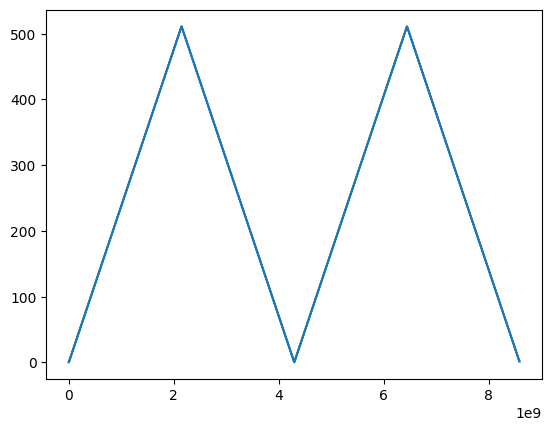

In [56]:
import matplotlib.pyplot as plt

prec = 9

test_vals = np.arange(2 ** 33, step=10000, dtype=np.uint64)

test_wave = test_vals.copy().astype(np.uint32)

wave_double = test_wave << 1

wave_double = wave_double - (wave_double >> prec)

#test_wave_ratio = wave_double - (wave_double >> prec)

tri = wave_double >> (32-prec)
tri[ test_wave>=(2 ** 31) ] ^= (2**prec)-1

plt.plot(test_vals, tri)


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df

,time_ms,read,filtered,result,locked,time_s
0,1020,83,0,83,0,1020
1,1021,83,83,83,0,1021
2,1022,83,83,83,0,1022
3,1024,82,82,82,0,1024
4,1026,82,82,82,0,1026
...,...,...,...,...,...,...
27981,30948,795,794,794,0,30948
27982,30949,794,794,794,0,30949
27983,30950,795,794,794,0,30950
27984,30951,795,794,794,0,30951


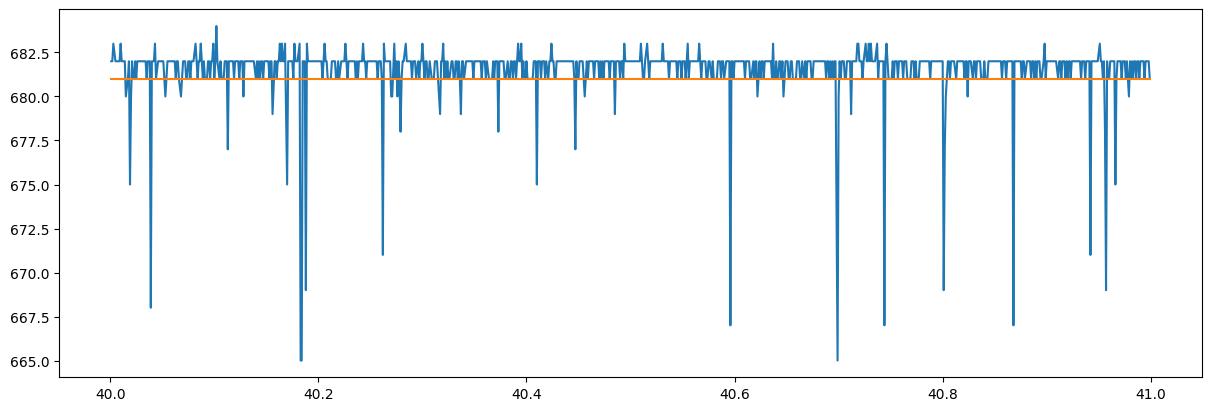

In [90]:
fig = plt.figure(figsize=(12, 4), layout="constrained")
plt.plot(df_disp['time_s'], df_disp['read'])
plt.plot(df_disp['time_s'], df_disp['filtered'])

In [5]:

from collections import deque
import numpy as np
 
 
class MedianKalmanFilter:
    """
    Etage 1 : filtre median glissant (fenetre impaire), qui absorbe les pics
              ponctuels sans biaiser la valeur en regime stable.
    Etage 2 : filtre de Kalman 1D sur un modele [position, vitesse] (derivee
              premiere), qui lisse le residu de bruit restant apres le median
              et permet de suivre les vraies variations du signal.
 
    Parametres
    ----------
    median_window : int
        Taille de la fenetre du filtre median (impair recommande, ex: 3 ou 5).
        Mettre a 1 pour desactiver le median et ne garder que le Kalman.
    q : float
        Bruit de process (Q). Plus grand => le filtre suit plus vite les
        variations reelles, mais lisse moins le bruit residuel.
    r : float
        Bruit de mesure (R). Plus grand => le filtre fait moins confiance a
        chaque nouvelle mesure, donc lisse davantage mais reagit plus lentement.
    dt : float
        Pas de temps entre deux appels a update() (en secondes, ou en unites
        coherentes avec votre vitesse). Si vous n'avez pas de vitesse physique
        a interpreter, dt=1.0 convient (la "vitesse" est alors en unites/appel).
    """
 
    def __init__(self, median_window: int = 9, q: float = .5, r: float = 500.0, dt: float = 1.0):
        assert median_window >= 1
        self.median_window = median_window
        self.buffer = deque(maxlen=median_window)
 
        self.dt = dt
        # Etat : [position, vitesse]
        self.x = np.array([0.0, 0.0])
        # Covariance d'estimation initiale (grande incertitude au demarrage)
        self.P = np.array([[1e3, 0.0],
                            [0.0, 1e3]])
 
        # Modele de transition (position += vitesse * dt ; vitesse constante)
        self.F = np.array([[1.0, dt],
                            [0.0, 1.0]])
 
        # On mesure uniquement la position
        self.H = np.array([[1.0, 0.0]])
 
        # Bruit de process (affecte surtout la vitesse, qui elle-meme
        # influence la position au pas suivant) - matrice Q classique
        # pour un modele a acceleration blanche
        self.Q = q * np.array([[dt**4 / 4, dt**3 / 2],
                                [dt**3 / 2, dt**2]])
 
        # Bruit de mesure (scalaire, une seule mesure)
        self.R = np.array([[r]])
 
        self._initialized = False
 
    def _median(self, value: float) -> float:
        self.buffer.append(value)
        if len(self.buffer) < self.median_window:
            # Pas encore assez d'echantillons : on renvoie la valeur brute
            return value
        return float(np.median(self.buffer))
 
    def update(self, raw_value: float) -> float:
        # --- Etage 1 : median ---
        med_value = self._median(raw_value)
 
        # --- Initialisation Kalman sur le premier echantillon utile ---
        if not self._initialized:
            self.x = np.array([med_value, 0.0])
            self._initialized = True
            return self.x[0]
 
        # --- Etage 2 : Kalman (prediction + correction) ---
        # Prediction
        x_pred = self.F @ self.x
        P_pred = self.F @ self.P @ self.F.T + self.Q
 
        # Innovation (ecart entre mesure et prediction)
        y = med_value - (self.H @ x_pred)[0]
        S = (self.H @ P_pred @ self.H.T + self.R)[0, 0]
        K = (P_pred @ self.H.T) / S  # gain de Kalman (vecteur 2x1)
 
        # Correction
        self.x = x_pred + (K.flatten() * y)
        self.P = P_pred - np.outer(K.flatten(), self.H @ P_pred)
 
        return self.x[0]
 
    @property
    def velocity(self) -> float:
        """Estimation courante de la derivee (utile si besoin de la pente)."""
        return self.x[1]


In [73]:
class TopQuantile:
    
    def __init__(self, median_window: int=7, top_quant: int=4):
        assert median_window >= 1
        assert top_quant <= median_window
        self.median_window = median_window
        self.top_quant = top_quant
        self.buffer = deque(maxlen=median_window)

    def update(self, raw_value):
        self.buffer.append(raw_value)
        if len(self.buffer) < self.median_window:
            # Pas encore assez d'echantillons : on renvoie la valeur brute
            return raw_value
        return sorted(self.buffer)[self.top_quant]
        #return float(np.median(self.buffer))


class MegaFilter:    
    def __init__(self, quantile_window_1: int=7, top_quant_1: int=4, quantile_window_2: int=5, top_quant_2: int=3, time_to_lock: int=2000, time_to_unlock: int=18, stable_interv: int=3):
        assert quantile_window_1 >= 1
        assert quantile_window_2 >= 1
        assert top_quant_1 <= quantile_window_1
        assert top_quant_1 <= quantile_window_2
        assert quantile_window_2 <= quantile_window_1
        assert time_to_lock > 0
        assert time_to_unlock > 0
        assert stable_interv > 0
        
        self.quantile_window_1 = quantile_window_1
        self.quantile_window_2 = quantile_window_2
        self.top_quant_1 = top_quant_1
        self.top_quant_2 = top_quant_2
        self.med_buffer_1 = deque(maxlen=quantile_window_1)
        self.med_buffer_2 = deque(maxlen=quantile_window_2)
        self.time_to_lock = time_to_lock
        self.time_to_unlock = time_to_unlock
        self.stable_interv = stable_interv
        self.locked = False
        self.lock_value = 0
        self.filtered_value = 0
        self.last_new_value_time = 0
        self.last_stable_value_time = 0

    def update(self, raw_value, time):
        self.med_buffer_1.append(raw_value)

        if len(self.med_buffer_1) < self.quantile_window_1:
            # Pas encore assez d'echantillons : on renvoie la valeur brute
            self.med_buffer_2.append(raw_value)
            self.filtered_value = raw_value
            self.last_new_value_time = time
            return raw_value

        # doing the filtering
        med_filtered_1 = sorted(self.med_buffer_1)[self.top_quant_1]

        self.med_buffer_2.append(med_filtered_1)

        self.filtered_value = sorted(self.med_buffer_2)[self.top_quant_2]

        # comparing the new filtered value to the previous value to determine if we're in lock mode
        stable = (self.filtered_value <= self.lock_value + self.stable_interv) and (self.filtered_value >= self.lock_value - self.stable_interv)

        if not stable and not self.locked:
            # unstable and not locked : record the new value, update the time
            self.lock_value = self.filtered_value
            self.last_new_value_time = time
            return self.filtered_value

        elif stable and not self.locked:
            # we may be in a stable mode and switch to lock mode
            if time - self.last_new_value_time > self.time_to_lock:
                # we've been stable for long enough, switch to lock mode
                # update the lock value to reflect the exact value
                self.lock_value = self.filtered_value
                self.locked = True
                print(f"locked at time {time}")
                self.last_stable_value_time = time
                return self.lock_value
            else:
                # don't do nothing and let the time pass, but don't update the last_new_value data
                return self.filtered_value
        
        elif stable and self.locked:
            # stable and in lock mode : return the lock value
            self.last_stable_value_time = time
            return self.lock_value
        
        elif not stable and self.locked:
            # maybe we need to leave the locked mode
            if time > self.last_stable_value_time + self.time_to_unlock:
                # too much instability, leave the lock mode
                self.locked = False
                print(f"unlocked at time {time}")
                self.last_new_value = time
                return self.filtered_value
            else:
                # not unstable enough, return the lock value
                return self.lock_value

        

  

In [90]:
df = pd.read_csv('pot_values_seq_4.csv')
df['time_s'] = df['time_ms'] / 1000

#df_disp = df
#df_disp = df[(df['time_s']>40) & (df['time_s']<41)]

In [91]:

kalman = MedianKalmanFilter()
out_with_median = [kalman.update(v) for v in df['read'].to_list()]
df['kalman'] = out_with_median

topquant = TopQuantile(median_window=9, top_quant=5)
topquant_2 = TopQuantile(median_window=5, top_quant=3)
out_with_top_quant = [topquant.update(v) for v in df['read'].to_list()]
out_with_top_quant_2 = [topquant_2.update(v) for v in out_with_top_quant]
df['top_quant'] = out_with_top_quant
df['top_quant_2'] = out_with_top_quant_2

megafilt = MegaFilter()
read_list = df['read'].to_list()
times_list = df['time_ms'].to_list()
out_with_megafilt = []
for k in range(len(read_list)):
    out_with_megafilt.append(megafilt.update(read_list[k],times_list[k]))

#out_with_megafilt = [megafilt.update(v) for v in df['read'].to_list()]
df['megafilt'] = out_with_megafilt

locked at time 5038
unlocked at time 14568
locked at time 17994


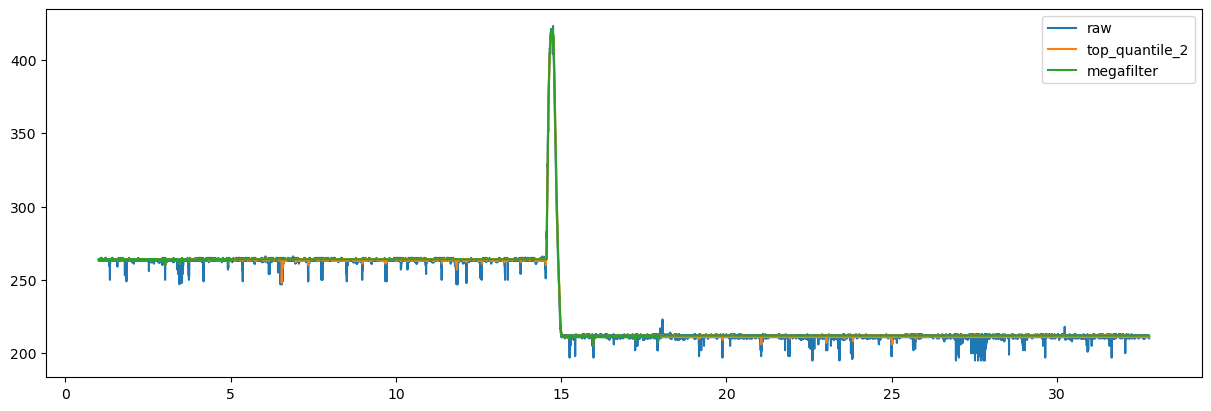

In [92]:
df_disp = df
# df_disp = df[(df['time_s']>37) & (df['time_s']<38)]

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(df_disp['time_s'], df_disp['read'], label='raw')
#ax.plot(df_disp['time_s'], df_disp['filtered'], label='current_filter')
#ax.plot(df_disp['time_s'], df_disp['kalman'], label='kalman')
#ax.plot(df_disp['time_s'], df_disp['top_quant'], label='top_quantile')
ax.plot(df_disp['time_s'], df_disp['top_quant_2'], label='top_quantile_2')
ax.plot(df_disp['time_s'], df_disp['megafilt'], label='megafilter')
ax.legend()
